# Two channels, shared assignments

Cluster both recorded channels and compare SNR-based with uniform output weighting.

Both outputs share cluster assignments while retaining output-specific GP/LDS states. This is not a model with a full cross-output covariance. share_gp=False does not mean shared or unshared C.


## Colab setup
      CPU only. Run all cells in order. No source edits are needed. Until the new
      package is published, upload `hdpgpc-colab.zip` when prompted; GitHub main
      currently contains the old API. Locally, open this notebook from the checkout
      after installing `.[tutorials]`. See the README for the bundle/build command.

      The setup reuses a supported local installation or installs the wheel in a
      private environment. On an unsupported host Python it downloads Python 3.11
      with uv. Dependencies need internet and may take several minutes on first use.
      The bundle contains only the small record 100, not the full dataset.

      `%%hdpgpc` executes ordinary Python in one persistent isolated worker and
      displays its figures here. This avoids changing Colab's preloaded NumPy/Torch
      or requiring a restart. Keep the prefix when adding a cell. Host-cell variables
      and worker variables are separate. Model code below uses public APIs only.


In [1]:
from pathlib import Path
import runpy
import zipfile
import hashlib
import json

# A local checkout or the previously uploaded bundle is reused automatically.
roots = [Path.cwd() / '.hdpgpc-colab-bundle', Path.cwd(), *Path.cwd().parents]
tutorial_root = next((p for p in roots if (p / 'examples/colab_setup.py').is_file()), None)
if tutorial_root is None:
    from google.colab import files
    print('Upload hdpgpc-colab.zip (the current wheel, shared helpers and record 100).')
    uploaded = files.upload()
    archive_path = next(Path(name) for name in uploaded if name.endswith('.zip'))
    tutorial_root = (Path.cwd() / '.hdpgpc-colab-bundle').resolve()
    with zipfile.ZipFile(archive_path) as archive:
        assert sum(item.file_size for item in archive.infolist()) < 20_000_000
        for item in archive.infolist():
            assert (tutorial_root / item.filename).resolve().is_relative_to(tutorial_root)
        archive.extractall(tutorial_root)
    manifest = json.loads((tutorial_root / 'manifest.json').read_text())
    for name, expected in manifest.items():
        path = (tutorial_root / name).resolve()
        assert path.is_relative_to(tutorial_root)
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, name
runpy.run_path(str(tutorial_root / 'examples/colab_setup.py'))['start'](tutorial_root)


HDP-GPC CPU worker: C:\Users\Adrian\Projects\Thesis\gpexplore\.release-current\Scripts\python.exe
Run the remaining %%hdpgpc cells in order; variables persist between cells.


## Imports and reproducibility


In [2]:
%%hdpgpc
import json
import time
import io
from contextlib import redirect_stdout
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from hdpgpc import HDPGPC, HDPGPCConfig
from hdpgpc.config import (HDPConfig, GPEmissionConfig, DynamicsConfig,
                          AlignmentConfig, InferenceConfig, MultiOutputConfig, NumericalConfig)

numerics = NumericalConfig(cuda=False, seed=42, num_threads=1,
                           dtype='float64', deterministic=True)
numerics.apply()  # Python, NumPy, PyTorch and Pyro RNGs; float64 and one CPU thread
versions = utils['environment']()


{
  "python": "3.11.14",
  "platform": "Windows-10-10.0.26200-SP0",
  "versions": {
    "hdpgpc": "0.2.0",
    "numpy": "1.26.4",
    "scipy": "1.14.1",
    "torch": "2.9.0",
    "gpytorch": "1.13",
    "linear-operator": "0.5.3",
    "pyro-ppl": "1.8.6",
    "scikit-learn": "1.5.2"
  }
}


C:\Users\Adrian\Projects\Thesis\gpexplore\.release-current\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load and inspect the record
      We use six consecutive beats from the same region as `test_step.ipynb`, not
      the original 250-beat demonstration. The stored tensor is (beats, points,
      channels). Channel names and physical units are not encoded in this array;
      we call them channel 0 and channel 1 rather than inventing metadata.

      Every sixth point is retained for 15-point CPU fits. The grid is rescaled to
      0–4 and amplitudes use first-beat centering/scaling. These are explicit teaching
      choices: coarse subsampling can discard morphology and is not a production
      resampling recommendation. Hyperparameters below are in these scaled units.
      The annotation file has a different length, so it is not used as ground truth.


Waveforms: (2272, 90, 2) float64 ; annotations: (2273,)
Annotation lengths differ: no ground-truth pairing or accuracy claim.
Model input (observations, points, outputs): (6, 15, 2)
Center: [ 0.3        -5.23333333] Scale: [64.65828124 45.21337069]


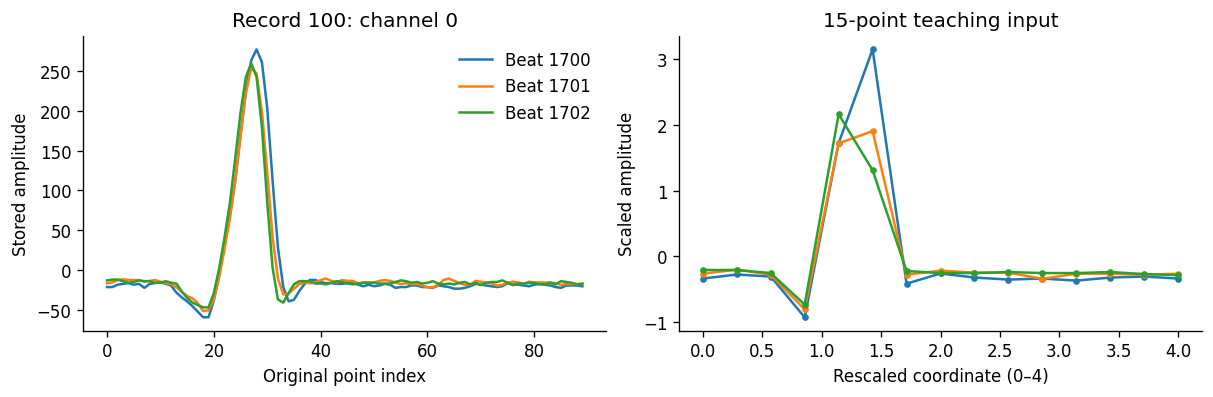

In [3]:
%%hdpgpc
N_OUTPUTS = 2
record, annotations = utils['load_record']()
start, n_beats, stride = 1700, 6, 6
raw = record[start:start + n_beats]
sampled = raw[:, ::stride, :]
# Freeze preprocessing using the first observed beat; do not peek at future beats.
center = sampled[0].mean(axis=0)
scale = sampled[0].std(axis=0)
assert np.all(scale > 0)
scaled = (sampled - center) / scale
grid = np.linspace(0., 4., sampled.shape[1])[:, None]
X = scaled[:, :, :N_OUTPUTS].copy()
print('Model input (observations, points, outputs):', X.shape)
print('Center:', center, 'Scale:', scale)
utils['plot_input'](raw, grid, X)
plt.show()


## Configure the model
      Both outputs share cluster assignments while retaining output-specific GP/LDS states. This is not a model with a full cross-output covariance. share_gp=False does not mean shared or unshared C.

      The GP starts with length scale 0.5 (bounds 0.1–2), output scale 1,
      observation covariance scale 0.04 and process scale 0.03. For static models
      the static policy initializes zero process covariance despite the supplied
      positive legacy `ini_gamma`. Bounds and Bayesian learning are explicit below.
      These are small teaching settings, not package defaults or the old notebook's
      raw-amplitude output scale 300. HDP concentration preset `balanced` and
      `max_models=4` bound this small exploration; the latter is not a known class count.

      Two batch outer iterations avoid a known empty-cluster reallocation failure
      reached with three on this subset (see inventory). They still allow repeated
      local/global updates. Do not interpret this cap as convergence. Inner GP and
      warp optimizer behavior is unchanged. Online schedules do not use this cap.


In [4]:
%%hdpgpc
config = HDPGPCConfig(
    x_basis=grid, verbose=False,
    hdp=HDPConfig(M=1, hdp_hyp='balanced', hmm_switch=True, max_models=4),
    emission=GPEmissionConfig(ini_lengthscale=0.5, bound_lengthscale=(0.1, 2.0),
        ini_outputscale=1.0, ini_sigma=0.04, bound_sigma=(0.005, 0.08),
        inducing_points=False),
    dynamics=DynamicsConfig(model_type='dynamic', ini_gamma=0.03,
        bound_gamma=(0.001, 0.1), annealing=False, bayesian_params=True,
        estimation_limit=None, reest_conditions=[1, 20, 5]),
    alignment=AlignmentConfig(policy='none', x_basis_warp=grid,
        noise_warp=0.01, bound_noise_warp=(0.001, 0.1), recursive_warp=False,
        warp_updating=False, method_compute_warp='greedy', mode_warp='rough'),
    inference=InferenceConfig(schedule='offline', with_warp=False, warp=False,
        it_limit=2, n_explore_steps=2,
        reestimate_initial_params=False),
    multi_output=MultiOutputConfig(n_outputs=2, use_snr=True,
        share_gp=False, reduce_outputs=False),
    numerics=numerics,
)
config.validate(for_build=True)
print(json.dumps(config.to_dict(), indent=2))


{
  "schema_version": 1,
  "x_basis": {
    "__type__": "ndarray",
    "dtype": "<f8",
    "shape": [
      15,
      1
    ],
    "values": {
      "__type__": "list",
      "items": [
        {
          "__type__": "list",
          "items": [
            0.0
          ],
          "__id__": 2
        },
        {
          "__type__": "list",
          "items": [
            0.2857142857142857
          ],
          "__id__": 3
        },
        {
          "__type__": "list",
          "items": [
            0.5714285714285714
          ],
          "__id__": 4
        },
        {
          "__type__": "list",
          "items": [
            0.8571428571428571
          ],
          "__id__": 5
        },
        {
          "__type__": "list",
          "items": [
            1.1428571428571428
          ],
          "__id__": 6
        },
        {
          "__type__": "list",
          "items": [
            1.4285714285714284
          ],
          "__id__": 7
        },
 

## Run inference
Legacy progress prints are captured to keep the tutorial readable; inspect `progress.getvalue()` if needed. No exceptions are suppressed.


In [5]:
%%hdpgpc
model = HDPGPC(config)
progress = io.StringIO()
extra = dict(preprocessing=dict(start=start, n_beats=n_beats, stride=stride,
                               center=center.tolist(), scale=scale.tolist()))
started = time.perf_counter()
with redirect_stdout(progress):
    model.fit(X)
inference_seconds = time.perf_counter() - started
print('Labels:', model.labels_, '; represented clusters:', model.n_clusters_)


Labels: [0 0 0 1 1 1] ; represented clusters: 2


## Inspect and plot public results
      Cluster IDs are current indices, not stable biological labels. `n_clusters_`
      counts represented clusters rather than reserved empty slots. Soft posterior
      assignment probabilities are not retained by this API: online
      `assignment_probabilities` is `None`, and `responsibilities` is hard.

      `predictive()` returns the current observation distribution, not a future
      forecast. Shading is ±2 square roots of the returned covariance diagonal;
      at the native grid this is the implementation's observation Sigma, not a
      newly reconstructed full posterior uncertainty or calibrated clinical interval.
      `posterior()` copies the latest stored filtered/smoothed states. Querying it
      does not run another smoother. No A/C matrices or transition probabilities
      are exposed by the facade, so we do not reach into private state to plot them.


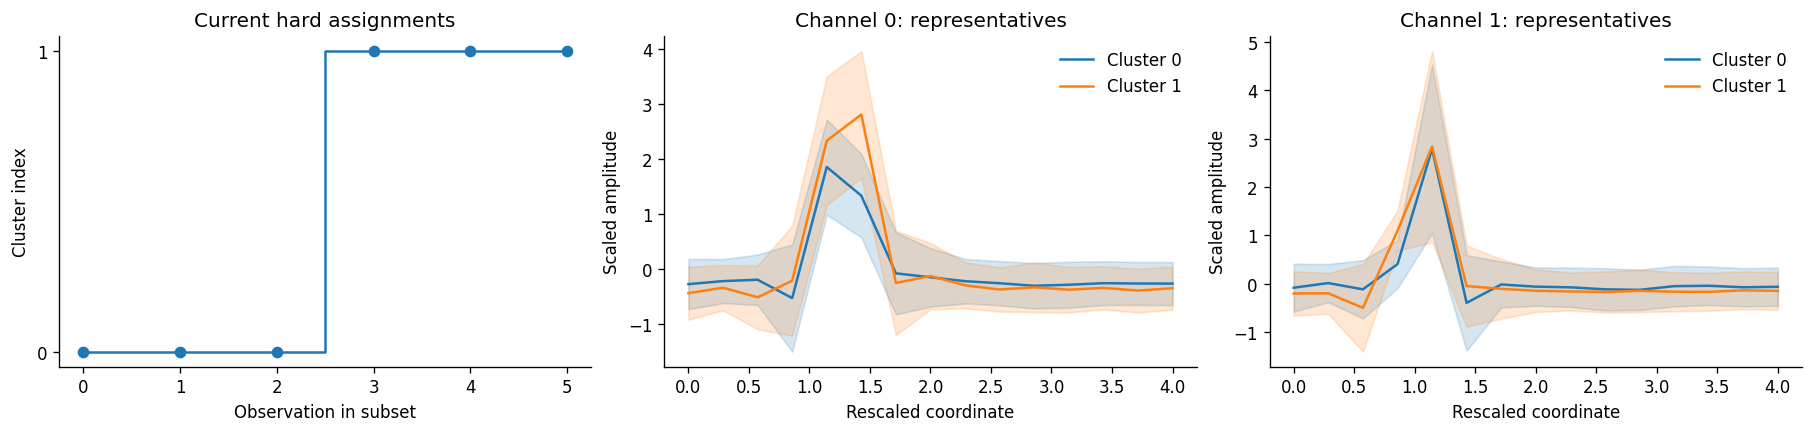

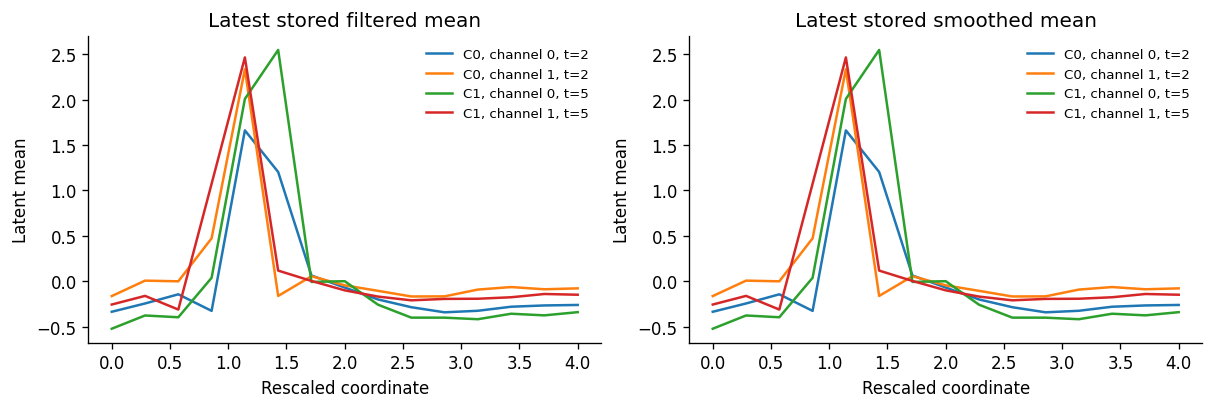

In [6]:
%%hdpgpc
utils['plot_results'](model, X)
plt.show()
utils['plot_latent'](model)
plt.show()


## A controlled comparison
Change only output weighting.


In [7]:
%%hdpgpc
comparison_config = replace(config, multi_output=replace(config.multi_output, use_snr=False))
comparison = HDPGPC(comparison_config)
comparison_started = time.perf_counter()
with redirect_stdout(io.StringIO()):
    comparison.fit(X)
print('Comparison seconds:', time.perf_counter() - comparison_started)
print('Main labels:', model.labels_, 'Comparison labels:', comparison.labels_)
extra['comparison'] = utils['snapshot'](comparison)


Comparison seconds: 8.477486800009501
Main labels: [0 0 0 1 1 1] Comparison labels: [0 0 0 1 1 2]


## What changed relative to the simplest baseline?

Compared with static clustering, model_type changes to dynamic, allowing evolving component states and parameter updates. Filtering/smoothing and LDS estimation add work; posterior snapshots show the latest latent estimates. A second output adds separate GP/LDS work and channel-specific plots. Both channels still share one label per beat; SNR weighting is a model choice, not preprocessing.


## Save the reproducible experiment
The JSON contains the full configuration, record/input hashes, environment, labels and public posterior quantities. Rerunning replaces only this tutorial’s generated report.


In [8]:
%%hdpgpc
report = utils['save_report']('06_multioutput', model, X, config, versions, inference_seconds, extra)
assert len(report['scientific_result']['labels']) == len(X)


Saved tutorial-results\06_multioutput.json ; inference seconds: 8.529


## When should I use this mode?

- Use when simultaneous channels should share one cluster identity.
- Scale channels deliberately; weighting does not replace a units decision.
- Compare uniform and SNR weighting when channels differ in quality.
- Inspect every output; this model does not expose full cross-channel predictive covariance.


## Optional exercises (outside the reproducible main flow)
      - Copy the configuration with `dataclasses.replace` and compare `hdp_hyp='less'`
        or `'more'`; leave the data and seed fixed and report resulting labels.
      - Try a different length scale or an explicit supported scikit-learn GP kernel;
        adjust its units to the grid and retain positive covariance bounds.
      - Compare `hmm_switch=False` with True. This changes assignment dependence,
        independently of static versus dynamic component behavior.
      - For alignment, compare `policy='none', warp=False`; for two channels, inspect
        the uniform/SNR comparison. Do not reinterpret `share_gp` as a C-sharing switch.
      - Increase observations or grid resolution in a separate copy and measure runtime.
        The known three-pass empty-cluster failure must be investigated before simply
        raising the outer iteration cap on this subset.

      PCA, user transform hooks and shared-C/fixed-LDS presets are not currently
      implemented by this public API; no corresponding exercise is silently simulated.


In [9]:
%%hdpgpc
plt.close('all')
